<a href="https://colab.research.google.com/github/Mohsi777999/Machine-Learning-Labs/blob/main/Lab_07_K-Nearest_Neighbors.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

**By Mohsin Ali**

## Lab Tasks

### Task 1 & 2: Load the Dataset and Apply Preprocessing

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.datasets import load_iris
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, classification_report, confusion_matrix

# Load the Iris dataset
iris = load_iris()
X = pd.DataFrame(iris.data, columns=iris.feature_names)
y = iris.target

# Preprocessing: Standardize features (crucial for distance-based algorithms like KNN)
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

print("Features structure:")
display(X.head())
print(f"Target classes: {iris.target_names}")

Features structure:


,sepal length (cm),sepal width (cm),petal length (cm),petal width (cm)
0,5.1,3.5,1.4,0.2
1,4.9,3.0,1.4,0.2
2,4.7,3.2,1.3,0.2
3,4.6,3.1,1.5,0.2
4,5.0,3.6,1.4,0.2


Target classes: ['setosa' 'versicolor' 'virginica']


### Task 3: Split the Dataset into Training and Testing Sets

In [2]:
X_train, X_test, y_train, y_test = train_test_split(
    X_scaled, y, test_size=0.3, random_state=42, stratify=y
)

print(f"Training set shape: {X_train.shape}")
print(f"Testing set shape: {X_test.shape}")

Training set shape: (105, 4)
Testing set shape: (45, 4)


### Task 4, 5 & 6: Train KNN with Different K Values, Make Predictions, and Evaluate

In [3]:
k_values = [3, 5, 7]

for k in k_values:
    # Initialize and train the model
    knn = KNeighborsClassifier(n_neighbors=k)
    knn.fit(X_train, y_train)

    # Make predictions
    y_pred = knn.predict(X_test)

    # Evaluate performance
    accuracy = accuracy_score(y_test, y_pred)
    precision = precision_score(y_test, y_pred, average='macro')
    recall = recall_score(y_test, y_pred, average='macro')
    f1 = f1_score(y_test, y_pred, average='macro')

    print(f"=== KNN Performance Evaluation (K = {k}) ===")
    print(f"Accuracy : {accuracy:.4f}")
    print(f"Precision: {precision:.4f}")
    print(f"Recall   : {recall:.4f}")
    print(f"F1-Score : {f1:.4f}\n")

=== KNN Performance Evaluation (K = 3) ===
Accuracy : 0.9111
Precision: 0.9298
Recall   : 0.9111
F1-Score : 0.9095

=== KNN Performance Evaluation (K = 5) ===
Accuracy : 0.9111
Precision: 0.9298
Recall   : 0.9111
F1-Score : 0.9095

=== KNN Performance Evaluation (K = 7) ===
Accuracy : 0.9333
Precision: 0.9444
Recall   : 0.9333
F1-Score : 0.9327



### Task 7: Test How Accuracy Changes Across a Wider Range of K

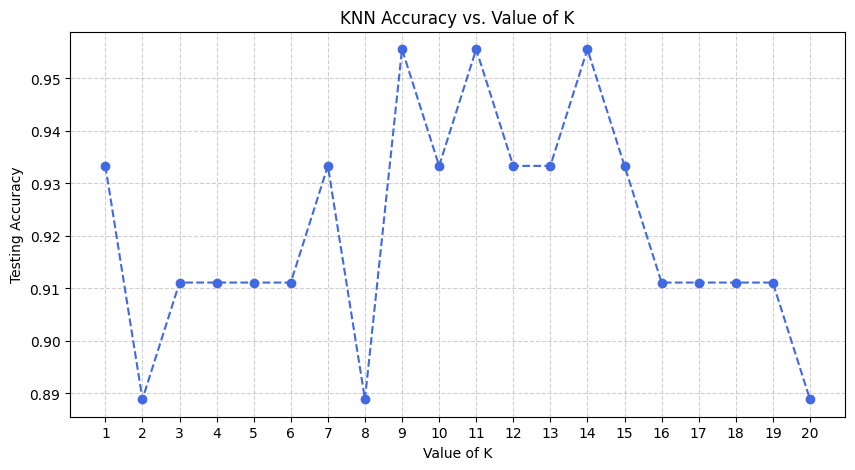

In [4]:
k_range = range(1, 21)
accuracies = []

for k in k_range:
    knn = KNeighborsClassifier(n_neighbors=k)
    knn.fit(X_train, y_train)
    y_pred = knn.predict(X_test)
    accuracies.append(accuracy_score(y_test, y_pred))

# Plotting the results
plt.figure(figsize=(10, 5))
plt.plot(k_range, accuracies, marker='o', linestyle='dashed', color='royalblue')
plt.title('KNN Accuracy vs. Value of K')
plt.xlabel('Value of K')
plt.ylabel('Testing Accuracy')
plt.xticks(k_range)
plt.grid(True, linestyle='--', alpha=0.6)
plt.show()